# Testing ideas to trim down links. 

Last update : 03.26.2025
Version: 0.01


<!-- ![Link trimming diagram](../notes/trim_links.jpg) -->
<img src="../notes/trim_links.jpg" alt="Drawing" style="width: 200px;"/>


In [166]:
import networkx as nx
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt

# Create test graph sets

In [171]:
# create test cases for the link trimming.

G1 = nx.DiGraph()
G1.add_nodes_from(["A", "B", "C", "D"])
G1.add_edge("A", "B", weight=1)
G1.add_edge("B", "C", weight=1)
G1.add_edge("C", "D", weight=1)

G2 = nx.DiGraph()
G2.add_nodes_from(["A", "D"])
G2.add_edge("A", "D", weight=1)

G3 = nx.DiGraph()
G3.add_nodes_from(["A", "C", "D", "E"])
G3.add_edge("A", "C", weight=1)
G3.add_edge("C", "D", weight=1)
G3.add_edge("E", "A", weight=1)

G4 = nx.DiGraph()
G4.add_nodes_from(["A", "E"])
G4.add_edge("A", "E", weight=1)

G_Raw = nx.DiGraph()
G_Raw.add_nodes_from(["A", "B", "C", "D", "E"])
G_Raw.add_edge("A", "B", weight=1)
G_Raw.add_edge("B", "C", weight=1)
G_Raw.add_edge("C", "D", weight=1)
G_Raw.add_edge("A", "D", weight=1)
G_Raw.add_edge("A", "E", weight=1)
G_Raw.add_edge("E", "A", weight=1)

G_Trimmed = nx.DiGraph()
G_Trimmed.add_nodes_from(["A", "C", "D", "E"])
G_Trimmed.add_edge("A", "C", weight=1)
G_Trimmed.add_edge("C", "D", weight=1)
G_Trimmed.add_edge("A", "E", weight=1)
G_Trimmed.add_edge("E", "A", weight=1)


G_test = nx.DiGraph()
G_test.add_nodes_from(["A", "B", "C", "D", "E"])
G_test.add_edge("A", "B", weight=1)
G_test.add_edge("B", "C", weight=1)
G_test.add_edge("C", "D", weight=1)
G_test.add_edge("A", "E", weight=1)
G_test.add_edge("E", "D", weight=1)

In [ ]:
# TODO: translate the strings to numbers to make it faster.
# use jax to make it faster.

# Code

In [63]:

def find_reachable_nodes(G, source, target):
    """
    Get all possible direct and indirect links between a source and target node.

    Args:
        G (nx.DiGraph): Input directed graph
        source (str): Source node
        target (str): Target node

    Returns:
        list: List of tuples containing all possible links (direct and indirect) 
              between source and target nodes


    Example:
        Given a graph G with nodes and edges: A -> B -> C -> D

        get_all_simple_paths(G, "A", "D") returns:
        [("A", "B"), ("B", "C"), ("C", "D")]
    """
    paths = list(nx.all_simple_paths(G, source, target))

    # create a list of all the possible links between the source and the target
    all_links = []
    for path in paths:
        for j in path:
            if source != j and path.index(source) < path.index(j):
                all_links.append((source, j))

    return all_links


find_reachable_nodes(G1, "A", "D")
# find_reachable_nodes(G2, "A", "D")
# find_reachable_nodes(G3, "A", "D")
# find_reachable_nodes(G4, "A", "D")

[('A', 'B'), ('A', 'C'), ('A', 'D')]

In [75]:
def get_all_possible_links(G):
    # Get all pairs of nodes at once using list comprehension
    node_pairs = [(source, target) for source in G.nodes()
                  for target in G.nodes() if source != target]

    # Process all pairs in one go using a list comprehension
    all_possible_links = set()
    for source, target in node_pairs:
        all_possible_links.update(find_reachable_nodes(G, source, target))

    return all_possible_links


get_all_possible_links(G1)
# get_all_possible_links(G2)
# get_all_possible_links(G3)
# get_all_possible_links(G4)

{('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'C'), ('B', 'D'), ('C', 'D')}

In [122]:

# get all the nodes and store them in numpy array
nodes = np.array(list(G1.nodes()))

# count the sum of the nodes appeared in G1-G4.


def count_node_appearances(list_of_graphs):

    # get all possible nodes in the list of graphs.
    # count the number of times each node appears in the list of graphs.
    # return a dictioary of the node name as key and the count as value.
    all_nodes = ()
    for graph in list_of_graphs:
        print("graph nodes: ", graph.nodes())
        all_nodes = set(all_nodes).union(graph.nodes())

    # count the number of times each node appears in the list of graphs.
    node_counts = {}
    for node in all_nodes:
        node_counts[node] = sum(node in graph.nodes()
                                for graph in list_of_graphs)

    return node_counts


node_counts = count_node_appearances([G1, G2, G3, G4])
print("node_counts: ", node_counts)
print("node_counts keys: ", list(node_counts.keys()))
print("node_counts values: ", np.array(list(node_counts.values())))

graph nodes:  ['A', 'B', 'C', 'D']
graph nodes:  ['A', 'D']
graph nodes:  ['A', 'C', 'D', 'E']
graph nodes:  ['A', 'E']
node_counts:  {'B': 1, 'C': 2, 'E': 2, 'D': 3, 'A': 4}
node_counts keys:  ['B', 'C', 'E', 'D', 'A']
node_counts values:  [1 2 2 3 4]


In [88]:
def trim_nodes(list_of_graphs, trim_node_threshold=1):

    nodeCounts = count_node_appearances(list_of_graphs)

    trimNodes = {node: count for node, count in nodeCounts.items()
                 if count > trim_node_threshold}

    return trimNodes


trim_nodes([G1, G2, G3, G4], 1)

{'C': 2, 'E': 2, 'D': 3, 'A': 4}

In [136]:
def count_edge_appearances(list_of_graphs):

    for graph in list_of_graphs:

        # all_possible_edges = ()

        # for graph in list_of_graphs:
        #     all_possible_edges = set(all_possible_edges).union(
        #         get_all_possible_links(graph))

        # print(all_possible_edges)

        edge_counts = defaultdict(int)
        for graph in list_of_graphs:
            for link in get_all_possible_links(graph):
                if link in edge_counts:
                    edge_counts[link] += 1
                else:
                    edge_counts[link] = 1
    print(edge_counts)
    return edge_counts


count_edge_appearances([G1, G2, G3, G4])

defaultdict(<class 'int'>, {('A', 'C'): 2, ('B', 'D'): 1, ('A', 'B'): 1, ('A', 'D'): 3, ('C', 'D'): 2, ('B', 'C'): 1, ('E', 'A'): 1, ('E', 'C'): 1, ('E', 'D'): 1, ('A', 'E'): 1})


defaultdict(int,
            {('A', 'C'): 2,
             ('B', 'D'): 1,
             ('A', 'B'): 1,
             ('A', 'D'): 3,
             ('C', 'D'): 2,
             ('B', 'C'): 1,
             ('E', 'A'): 1,
             ('E', 'C'): 1,
             ('E', 'D'): 1,
             ('A', 'E'): 1})

In [173]:
def trim_edges(list_of_graphs, trim_edge_threshold=0):
    edgeCounts = count_edge_appearances(list_of_graphs)

    trimmedNodes = trim_nodes(list_of_graphs, trim_node_threshold=1)

    trimEdges = {}
    for edge, count in edgeCounts.items():
        if (edge[0] in trimmedNodes or edge[1] in trimmedNodes) and count > trim_edge_threshold:
            trimEdges[edge] = count

    return trimEdges


trimmedGraph = trim_edges([G1, G2, G3, G4], 1)

defaultdict(<class 'int'>, {('A', 'C'): 2, ('B', 'D'): 1, ('A', 'B'): 1, ('A', 'D'): 3, ('C', 'D'): 2, ('B', 'C'): 1, ('E', 'A'): 1, ('E', 'C'): 1, ('E', 'D'): 1, ('A', 'E'): 1})
graph nodes:  ['A', 'B', 'C', 'D']
graph nodes:  ['A', 'D']
graph nodes:  ['A', 'C', 'D', 'E']
graph nodes:  ['A', 'E']


In [174]:
# turn the trimmedGraph back to a graph
# translate the trimmedGraph to a list of tuples
allEdges = []
for edge, count in trimmedGraph.items():
    EdgeWWeight = (edge[0], edge[1], count)
    allEdges.append(EdgeWWeight)


trimmedGraph = nx.DiGraph()
trimmedGraph.add_weighted_edges_from(allEdges)

# print the trimmedGraph
print(trimmedGraph.nodes())
print(trimmedGraph.edges())

['A', 'C', 'D']
[('A', 'C'), ('A', 'D'), ('C', 'D')]


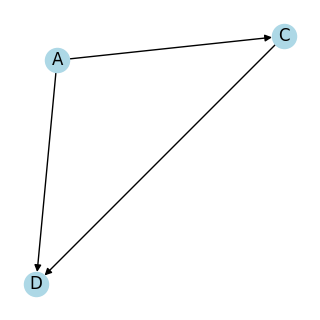

In [175]:
# print nx graph
# change the size of the graph

plt.figure(figsize=(3, 3))

nx.draw(trimmedGraph, with_labels=True, node_color="lightblue")

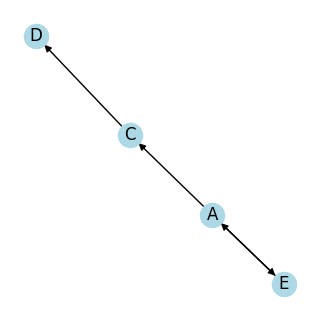

In [176]:
plt.figure(figsize=(3, 3))
nx.draw(G_Trimmed, with_labels=True, node_color="lightblue")

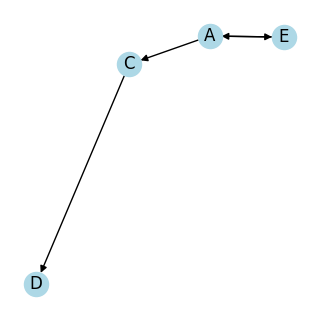

In [177]:
plt.figure(figsize=(3, 3))
nx.draw(G_Trimmed, with_labels=True, node_color="lightblue")

In [144]:
edge = ("A", "B")

if "C" in edge:
    print(True)
else:

    print(False)

for i in edge:
    print(i)

False
A
B
